In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from tqdm.notebook import tqdm
import cv2

import common

2024-03-20 17:37:47.812146: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-03-20 17:37:47.849950: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-20 17:37:48.755739: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [8]:
ds = common.load_dataset("data/training_25k_4.tfrecord", common.parse_feature)

0it [00:00, ?it/s]

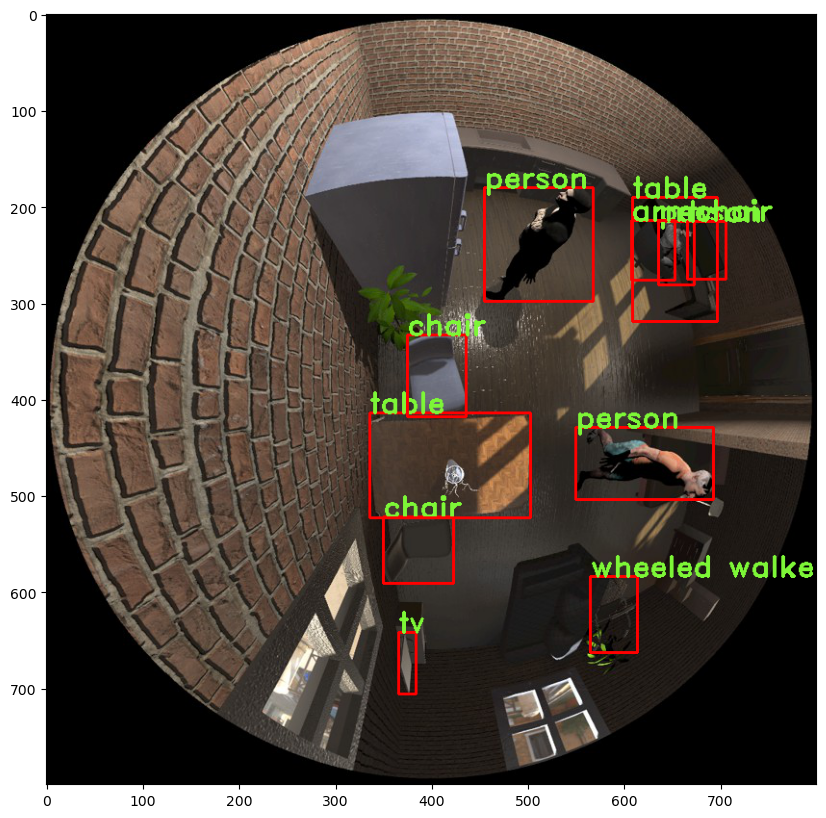

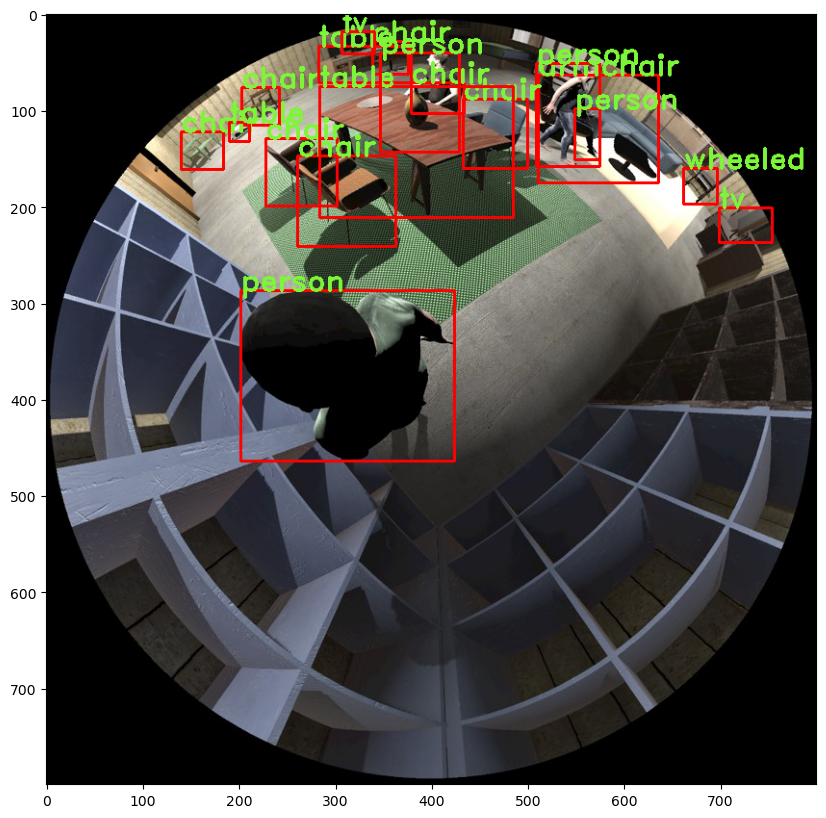

In [24]:
stop_count = 2
count = 0
for example in tqdm(ds):
    height = int(example['image/height'].values)
    width = int(example['image/width'].values)    

    img_id = (example['image/source_id'].numpy())
    key = example['image/key/sha256'].numpy()

    img_string = (example['image/encoded'].numpy())
    img_filename = (example['image/filename'].numpy()).decode('utf-8')

    pil_img = Image.open(BytesIO(img_string))
    img  = np.array(pil_img)

    bb_xmin = np.array(example['image/object/bbox/xmin'].values)
    bb_ymin = np.array(example['image/object/bbox/ymin'].values)
    bb_xmax = np.array(example['image/object/bbox/xmax'].values)
    bb_ymax = np.array(example['image/object/bbox/ymax'].values)
    classes = np.array(example['image/object/class/text'].values)
    labels = np.array(example['image/object/class/label'].values)

    for xmin, ymin, xmax, ymax, cl in zip(bb_xmin, bb_ymin, bb_xmax, bb_ymax, classes):

        x = int(round(xmin * width))
        y = int(round(ymin * height))
        x2 = int(round(xmax * width))
        y2 = int(round(ymax * height))
        cv2.rectangle(img, (x, y), (x2, y2), (255, 0, 0), 2)
        cv2.putText(
            img,
            cl.decode(),
            (x, y),
            fontFace = cv2.FONT_HERSHEY_DUPLEX,
            fontScale = 1.0,
            color = (125, 246, 55),
            thickness = 2
        )

        # here you can add yor logic or export function

    plt.figure(figsize=(10, 10))
    plt.imshow(img)

    count += 1
    if count >= stop_count:
        break
